<a href="https://colab.research.google.com/github/adalves-ufabc/2026.Q3-PLN/blob/main/2026_Q3_PLN_AULA_17_Notebook_37.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processamento de Linguagem Natural [2026-Q3]**
Prof. Alexandre Donizeti Alves

## **Geração de Dados Sintéticos [LangChain]**
---



**Dados sintéticos** são dados gerados artificialmente, em vez de dados coletados de eventos do mundo real. São usados para simular dados reais sem comprometer a privacidade ou enfrentar limitações do mundo real.



Benefícios dos Dados Sintéticos:

- **Privacidade e Segurança**: sem dados pessoais reais em risco de vazamentos.
- **Aumento de Dados**: expande conjuntos de dados para aprendizado de máquina.
- **Flexibilidade**: cria cenários específicos ou raros.
- **Custo-efetivo**: muitas vezes mais barato do que a coleta de dados reais.
- **Conformidade Regulatória**: ajuda a navegar em leis rigorosas de proteção de dados.
- **Robustez do Modelo**: pode levar a modelos de IA que generalizam melhor.
- **Prototipagem Rápida**: permite testes rápidos sem dados reais.
- **Experimentação Controlada**: simula condições específicas.
- **Acesso a Dados**: alternativa quando dados reais não estão disponíveis.

**NOTA**: apesar dos benefícios, os dados sintéticos devem ser usados com cuidado, pois podem não capturar sempre as complexidades do mundo real.

#### **LangChain**

In [ ]:
#@title Instalando o pacote LangChain
!pip install langchain

In [ ]:
#@title Versão do LangChain

import langchain

print(langchain.__version__)

1.4.8


In [ ]:
#@title Integração com o pacote da OpenAI

!pip install langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.9/588.9 kB 8.6 MB/s  0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain-openai]


In [ ]:
#@title Definindo a chave da API da OpenAI
from getpass import getpass

OPENAI_API_KEY = getpass()

··········


In [ ]:
#@title Definindo o modelo da API da OpenAI

from langchain_openai import ChatOpenAI

modelo = ChatOpenAI( model="gpt-6-luna", api_key=OPENAI_API_KEY )

#### **Exemplo 1 – Geração de dados sintéticos de clientes**

Neste primeiro exemplo, o modelo será solicitado a produzir informações fictícias sobre clientes de uma loja.

A geração será feita diretamente pelo modelo, utilizando uma instrução em linguagem natural.

In [ ]:
prompt = """
Gere 5 registros de clientes fictícios de uma loja.

Para cada cliente, informe:
- Nome
- Idade
- Cidade
- Profissão
- Produto de interesse

Os dados devem ser fictícios e variados.

Apresente o resultado em formato de lista.
"""

resposta = modelo.invoke(prompt)

In [ ]:
print(resposta.content)

1. **Nome:** Marina Costa  
   **Idade:** 29 anos  
   **Cidade:** Curitiba  
   **Profissão:** Designer gráfica  
   **Produto de interesse:** Câmera fotográfica  

2. **Nome:** Rafael Nogueira  
   **Idade:** 42 anos  
   **Cidade:** Recife  
   **Profissão:** Professor de história  
   **Produto de interesse:** Notebook  

3. **Nome:** Beatriz Almeida  
   **Idade:** 21 anos  
   **Cidade:** Goiânia  
   **Profissão:** Estudante de arquitetura  
   **Produto de interesse:** Fones de ouvido sem fio  

4. **Nome:** Carlos Eduardo Martins  
   **Idade:** 56 anos  
   **Cidade:** Florianópolis  
   **Profissão:** Chef de cozinha  
   **Produto de interesse:** Liquidificador profissional  

5. **Nome:** Luana Ferreira  
   **Idade:** 34 anos  
   **Cidade:** Belém  
   **Profissão:** Médica veterinária  
   **Produto de interesse:** Bicicleta elétrica


In [ ]:
from IPython.core.display import Markdown

display(Markdown(resposta.content))

1. **Nome:** Marina Costa  
   **Idade:** 29 anos  
   **Cidade:** Curitiba  
   **Profissão:** Designer gráfica  
   **Produto de interesse:** Câmera fotográfica  

2. **Nome:** Rafael Nogueira  
   **Idade:** 42 anos  
   **Cidade:** Recife  
   **Profissão:** Professor de história  
   **Produto de interesse:** Notebook  

3. **Nome:** Beatriz Almeida  
   **Idade:** 21 anos  
   **Cidade:** Goiânia  
   **Profissão:** Estudante de arquitetura  
   **Produto de interesse:** Fones de ouvido sem fio  

4. **Nome:** Carlos Eduardo Martins  
   **Idade:** 56 anos  
   **Cidade:** Florianópolis  
   **Profissão:** Chef de cozinha  
   **Produto de interesse:** Liquidificador profissional  

5. **Nome:** Luana Ferreira  
   **Idade:** 34 anos  
   **Cidade:** Belém  
   **Profissão:** Médica veterinária  
   **Produto de interesse:** Bicicleta elétrica

**Discussão didática**: observe que o modelo consegue produzir diferentes registros sem que seja necessário construir manualmente cada um deles.

Entretanto, existe uma limitação: a saída é um texto livre. Isso dificulta a utilização direta dos dados em operações com Pandas, por exemplo.

Uma alternativa é solicitar uma saída estruturada.

#### **Exemplo 2 – Geração de dados estruturados com Pydantic**

O `Pydantic` permite definir uma estrutura que os dados gerados devem seguir.

Neste exemplo, cada cliente terá cinco atributos.

In [ ]:
from pydantic import BaseModel, Field
from typing import List

class Cliente(BaseModel):
    nome: str = Field(description="Nome fictício do cliente")
    idade: int = Field(description="Idade entre 18 e 80 anos")
    cidade: str
    profissao: str
    produto_interesse: str

Podemos utilizar o recurso `with_structured_output()` do **LangChain**:

In [ ]:
gerador_cliente = modelo.with_structured_output(Cliente)

Agora, solicitamos a geração de um cliente:

In [ ]:
cliente = gerador_cliente.invoke(
    """
    Gere um cliente fictício brasileiro.
    Escolha uma profissão, uma cidade e um produto
    de interesse de maneira coerente.
    """
)

print(cliente)

nome='Marina Oliveira' idade=34 cidade='Curitiba' profissao='Designer de interiores' produto_interesse='Cadeira ergonômica'


A resposta será um objeto `Pydantic`, cujos atributos podem ser acessados individualmente:

In [ ]:
print("Nome:", cliente.nome)
print("Idade:", cliente.idade)
print("Cidade:", cliente.cidade)
print("Profissão:", cliente.profissao)
print("Produto:", cliente.produto_interesse)

Nome: Marina Oliveira
Idade: 34
Cidade: Curitiba
Profissão: Designer de interiores
Produto: Cadeira ergonômica


**O que mudou?**

Em vez de receber somente um texto, temos um objeto estruturado, que facilita a manipulação dos dados e sua integração com outras bibliotecas Python.

#### **Exemplo 3 – Geração de um conjunto de clientes**

Vamos ampliar o exemplo anterior e gerar 10 clientes fictícios.

Primeiro, definimos uma estrutura para representar uma coleção de clientes:

In [ ]:
class Clientes(BaseModel):
    clientes: List[Cliente]

Criamos o gerador:

In [ ]:
gerador_clientes = modelo.with_structured_output(Clientes)

Solicitamos os registros:

In [ ]:
resultado = gerador_clientes.invoke(
    """
    Gere 10 clientes fictícios brasileiros para uma loja
    de produtos eletrônicos.

    Requisitos:
    - Idades entre 18 e 70 anos.
    - Distribua os clientes entre diferentes cidades.
    - Utilize profissões variadas.
    - Considere diferentes interesses em produtos
      eletrônicos, como notebooks, celulares,
      tablets, televisores e acessórios.
    - Evite repetir nomes.
    - Os registros devem apresentar diversidade.
    """
)

Visualização:

In [ ]:
for cliente in resultado.clientes:
    print(
        cliente.nome,
        cliente.idade,
        cliente.cidade,
        cliente.profissao,
        cliente.produto_interesse
    )

Ana Beatriz Ferreira 24 São Paulo Designer gráfica Notebook
Lucas Henrique Santos 31 Salvador Professor de História Celular
Mariana Costa Almeida 19 Curitiba Estudante de Engenharia Tablet
Rafael Oliveira Mendes 42 Manaus Técnico em refrigeração Televisor
Camila Rodrigues Nunes 36 Recife Enfermeira Fones de ouvido sem fio
João Pedro Carvalho 58 Porto Alegre Contador Celular
Débora Martins Ribeiro 27 Goiânia Fotógrafa Câmera e acessórios
Bruno César Araújo 46 Belém Arquiteto Notebook
Sílvia Fernandes Barros 63 Florianópolis Aposentada Televisor
Mateus Lima Gonçalves 21 Fortaleza Assistente administrativo Acessórios para celular


**Transformando em DataFrame**

Uma vantagem de trabalhar com dados estruturados é a facilidade de integração com o Pandas.

In [ ]:
import pandas as pd

dados = [
    cliente.model_dump()
    for cliente in resultado.clientes
]

df = pd.DataFrame(dados)

display(df)

,nome,idade,cidade,profissao,produto_interesse
0,Ana Beatriz Ferreira,24,São Paulo,Designer gráfica,Notebook
1,Lucas Henrique Santos,31,Salvador,Professor de História,Celular
2,Mariana Costa Almeida,19,Curitiba,Estudante de Engenharia,Tablet
3,Rafael Oliveira Mendes,42,Manaus,Técnico em refrigeração,Televisor
4,Camila Rodrigues Nunes,36,Recife,Enfermeira,Fones de ouvido sem fio
5,João Pedro Carvalho,58,Porto Alegre,Contador,Celular
6,Débora Martins Ribeiro,27,Goiânia,Fotógrafa,Câmera e acessórios
7,Bruno César Araújo,46,Belém,Arquiteto,Notebook
8,Sílvia Fernandes Barros,63,Florianópolis,Aposentada,Televisor
9,Mateus Lima Gonçalves,21,Fortaleza,Assistente administrativo,Acessórios para celular


Podemos exportar o conjunto de dados:

In [ ]:
df.to_csv("clientes_sinteticos.csv", index=False)

df.to_json(
    "clientes_sinteticos.json",
    orient="records",
    force_ascii=False,
    indent=4
)

#### **Exemplo 4 – Geração de avaliações de produtos**

Este exemplo é interessante para uma aula de Processamento de Linguagem Natural, pois permite gerar dados textuais com rótulos de sentimentos.

Imagine que desejamos construir uma base de avaliações de produtos para posteriormente desenvolver um classificador de sentimentos.

In [ ]:
class Avaliacao(BaseModel):
    produto: str
    avaliacao: str
    nota: int = Field(ge=1, le=5)
    sentimento: str

In [ ]:
gerador_avaliacao = modelo.with_structured_output(Avaliacao)

In [ ]:
avaliacao = gerador_avaliacao.invoke(
    """
    Gere uma avaliação fictícia de um smartphone.

    A avaliação deve apresentar uma opinião
    coerente com a nota atribuída.

    O sentimento deve ser:
    positivo, neutro ou negativo.
    """
)

In [ ]:
avaliacao.model_dump()

{'produto': 'Smartphone fictício Aurora X5',
 'avaliacao': 'O Aurora X5 tem tela nítida, bateria que dura o dia todo e desempenho rápido para tarefas comuns. As fotos ficam boas em ambientes iluminados, mas perdem qualidade à noite. Pelo preço, é uma opção equilibrada, embora a câmera pudesse ser melhor.',
 'nota': 4,
 'sentimento': 'positivo'}

**Gerando avaliações com diferentes sentimentos**

Podemos gerar exemplos com características distintas:

In [ ]:
sentimentos = [
    "positivo",
    "positivo",
    "neutro",
    "negativo",
    "negativo"
]

avaliacoes = []

for sentimento in sentimentos:

    resultado = gerador_avaliacao.invoke(
        f"""
        Gere uma avaliação fictícia de um produto eletrônico.

        O sentimento deve ser {sentimento}.

        A nota deve ser coerente com o sentimento.
        Produza um texto natural, semelhante a uma
        avaliação escrita por um consumidor.
        """
    )

    avaliacoes.append(resultado.model_dump())

In [ ]:
df_avaliacoes = pd.DataFrame(avaliacoes)

display(df_avaliacoes)

,produto,avaliacao,nota,sentimento
0,Fone de ouvido Bluetooth PulseSound X2,Comprei este fone há algumas semanas e estou m...,5,positivo
1,Fone de ouvido Bluetooth WaveSound Pro,Comprei este fone há algumas semanas e estou m...,5,positivo
2,Fone de ouvido Bluetooth Orion S2,Uso o Orion S2 há algumas semanas. A conexão é...,3,neutro
3,Fone de ouvido sem fio PulseBeat X2,Comprei o PulseBeat X2 esperando uma boa exper...,2,negativo
4,Fone Bluetooth SoundBeat X2,Comprei este fone esperando uma boa experiênci...,2,negativo


#### **Exemplo 5 – Geração de chamados de suporte técnico**

Vamos trabalhar com uma aplicação mais próxima de um cenário real: a criação de uma base de chamados de suporte técnico.

O objetivo é gerar registros que poderiam ser utilizados para desenvolver um sistema de classificação automática de solicitações.

**Definição da estrutura**

In [ ]:
class Chamado(BaseModel):
    id: int
    categoria: str
    titulo: str
    descricao: str
    prioridade: str
    status: str

Definimos a estrutura de uma coleção:

In [ ]:
class Chamados(BaseModel):
    chamados: List[Chamado]

Criamos o gerador:

In [ ]:
gerador_chamados = modelo.with_structured_output(Chamados)

**Geração dos dados**

In [ ]:
resultado = gerador_chamados.invoke(
    """
    Gere 10 chamados fictícios para uma empresa de tecnologia.

    Considere as seguintes categorias:
    - Hardware
    - Software
    - Rede
    - Acesso
    - Segurança

    Para cada chamado, informe:
    - ID numérico
    - Categoria
    - Título
    - Descrição detalhada
    - Prioridade: baixa, média ou alta
    - Status: aberto, em andamento ou resolvido

    Crie situações variadas e realistas.

    Os IDs devem ser únicos.
    """
)

Transformação em DataFrame:

In [ ]:
dados = [
    chamado.model_dump()
    for chamado in resultado.chamados
]

df_chamados = pd.DataFrame(dados)

display(df_chamados)

,id,categoria,titulo,descricao,prioridade,status
0,1,Hardware,Notebook superaquecendo durante videoconferências,O notebook da equipe de projetos aquece bastan...,alta,aberto
1,2,Software,Aplicativo de folha de pagamento não exporta r...,Ao tentar exportar o relatório mensal em forma...,alta,em andamento
2,3,Rede,Wi-Fi instável na sala de treinamento,Os participantes da sala de treinamento relata...,média,aberto
3,4,Acesso,Conta bloqueada após tentativas de login,Uma analista teve a conta corporativa bloquead...,alta,aberto
4,5,Segurança,E-mail suspeito solicita atualização de creden...,Um colaborador recebeu um e-mail que aparenta ...,alta,em andamento
5,6,Hardware,Monitor com cintilação intermitente,O monitor da estação de atendimento apresenta ...,média,aberto
6,7,Software,Cliente de e-mail fecha ao abrir anexos,O cliente de e-mail encerra inesperadamente qu...,média,em andamento
7,8,Rede,Acesso lento ao servidor de arquivos,O carregamento e a cópia de documentos no serv...,média,aberto
8,9,Acesso,Permissão insuficiente em pasta compartilhada,Uma nova integrante da equipe de marketing con...,baixa,resolvido
9,10,Segurança,Alerta de login em localização desconhecida,O sistema de identidade corporativa registrou ...,alta,em andamento


**Possibilidades de utilização**

A base gerada pode ser utilizada em diferentes atividades:
1. Classificação automática dos chamados por categoria.
2. Classificação de prioridade utilizando processamento de linguagem natural.
3. Agrupamento de chamados semelhantes.
4. Identificação de problemas recorrentes.
5. Construção de modelos de previsão de prioridade.

Por exemplo, podemos explorar a distribuição dos chamados:

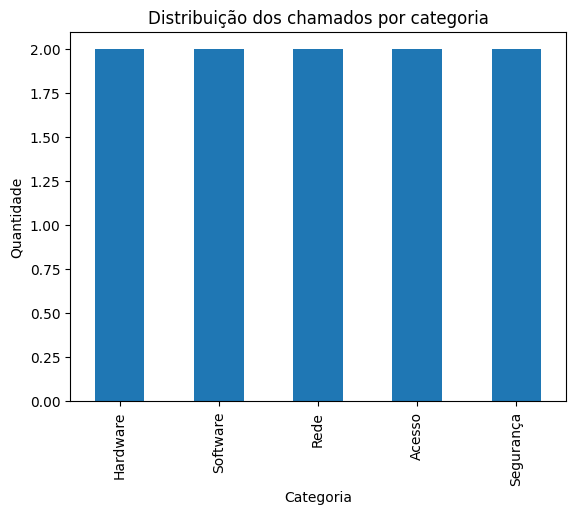

In [ ]:
import matplotlib.pyplot as plt

df_chamados["categoria"].value_counts().plot(
    kind="bar",
    title="Distribuição dos chamados por categoria"
)

plt.xlabel("Categoria")
plt.ylabel("Quantidade")
plt.show()

#### **Exemplo 6 – Geração de dados sintéticos com diversidade controlada**

In [ ]:
# Definição da estrutura

class Estudante(BaseModel):
    idade: int
    curso: str
    semestre: int
    horas_estudo_semanais: int
    trabalha: bool
    distancia_universidade_km: float
    situacao: str
    justificativa: str


class Estudantes(BaseModel):
    estudantes: List[Estudante]

In [ ]:
gerador_estudantes = modelo.with_structured_output(Estudantes)

In [ ]:
resultado = gerador_estudantes.invoke(
    """
    Gere 20 registros fictícios de estudantes universitários.

    Considere diferentes cursos de graduação.

    Características:
    - Idade entre 18 e 45 anos.
    - Semestre entre 1 e 10.
    - Horas de estudo semanais entre 2 e 40.
    - Indique se o estudante trabalha.
    - Distância da universidade entre 1 e 50 km.

    A situação acadêmica deve ser uma destas:
    - Regular
    - Em risco de evasão
    - Evadido

    Crie diversidade entre os registros.

    Considere que estudantes que trabalham, estudam
    poucas horas e enfrentam grandes deslocamentos
    podem apresentar maior dificuldade de permanência.

    Entretanto, não estabeleça uma relação determinística
    entre essas características e a situação acadêmica.

    A justificativa deve explicar brevemente a situação.
    """
)

In [ ]:
df_estudantes = pd.DataFrame(
    [e.model_dump() for e in resultado.estudantes]
)

display(df_estudantes)

,idade,curso,semestre,horas_estudo_semanais,trabalha,distancia_universidade_km,situacao,justificativa
0,19,Administração,2,18,False,6.5,Regular,Mantém rotina de estudos consistente e acompan...
1,24,Engenharia Civil,5,12,True,32.0,Regular,Apesar da conciliação entre trabalho e estudos...
2,21,Psicologia,4,8,True,18.0,Em risco de evasão,Relata dificuldades para acompanhar as ativida...
3,27,Enfermagem,6,22,True,8.0,Regular,Conta com uma rotina organizada e participa re...
4,20,Ciência da Computação,3,6,False,12.0,Em risco de evasão,Tem apresentado dificuldades em algumas discip...
5,31,Pedagogia,7,14,True,41.0,Regular,"Mesmo com deslocamento longo, demonstra persis..."
6,18,Design Gráfico,1,25,False,3.0,Regular,Está se adaptando bem ao início da graduação e...
7,35,Direito,8,9,True,47.0,Em risco de evasão,A conciliação de compromissos e o deslocamento...
8,22,Medicina Veterinária,5,30,False,15.0,Regular,Dedica tempo às atividades práticas e teóricas...
9,29,Ciências Contábeis,4,5,True,36.0,Evadido,Interrompeu o curso após dificuldades para con...


**Análise dos dados**

Podemos verificar a distribuição das situações acadêmicas:

In [ ]:
display(
    df_estudantes["situacao"].value_counts()
)

,count
situacao,
Regular,12
Em risco de evasão,5
Evadido,3


E comparar as horas de estudo por situação:

In [ ]:
display(
    df_estudantes.groupby("situacao")[
        "horas_estudo_semanais"
    ].mean()
)

,horas_estudo_semanais
situacao,
Em risco de evasão,8.600000
Evadido,8.333333
Regular,20.500000


#### **Exemplo 7 – Geração de dados a partir de exemplos existentes**

Até aqui, os dados foram produzidos a partir de instruções em linguagem natural.

Outra possibilidade é fornecer alguns exemplos ao modelo e solicitar que ele produza novos registros com características semelhantes.

Essa abordagem é particularmente interessante para demonstrar geração condicionada por exemplos (*few-shot generation*).

Considere os seguintes registros:

In [ ]:
exemplos = """
Exemplo 1:
Produto: Notebook
Avaliação: O equipamento é rápido e atende bem
às minhas necessidades de trabalho.
Nota: 5
Sentimento: positivo

Exemplo 2:
Produto: Smartphone
Avaliação: A bateria acaba muito rapidamente
e a câmera apresenta baixa qualidade.
Nota: 2
Sentimento: negativo

Exemplo 3:
Produto: Tablet
Avaliação: O produto funciona corretamente,
mas não apresenta nada de especial.
Nota: 3
Sentimento: neutro
"""

Agora, solicitamos novos registros seguindo o padrão:

In [ ]:
class Avaliacoes(BaseModel):
    avaliacoes: List[Avaliacao]

In [ ]:
gerador_avaliacoes = modelo.with_structured_output(Avaliacoes)

resultado = gerador_avaliacoes.invoke(
    f"""
    Considere os seguintes exemplos:

    {exemplos}

    Gere 10 novas avaliações fictícias de produtos
    eletrônicos.

    Mantenha a mesma estrutura dos exemplos.

    Utilize diferentes produtos, opiniões e notas.

    As avaliações devem apresentar diversidade textual
    e o sentimento deve ser coerente com a nota.
    """
)

In [ ]:
df = pd.DataFrame(
    [a.model_dump() for a in resultado.avaliacoes]
)

display(df)

,produto,avaliacao,nota,sentimento
0,Fone de ouvido sem fio,"O som é nítido, o encaixe é confortável e a ba...",5,positivo
1,Smart TV,A imagem é excelente e os aplicativos abrem ra...,4,positivo
2,Câmera digital,As fotos ficam escuras mesmo em ambientes bem ...,2,negativo
3,Caixa de som Bluetooth,"O volume é razoável e a conexão funciona, embo...",3,neutro
4,Teclado mecânico,As teclas são responsivas e a construção parec...,5,positivo
5,Impressora multifuncional,O equipamento trava com frequência e demora ba...,1,negativo
6,Relógio inteligente,"É confortável e monitora bem as atividades, ma...",4,positivo
7,Roteador Wi-Fi,"O sinal atende bem em cômodos próximos, mas fi...",3,neutro
8,Monitor,As cores parecem apagadas e a tela apresenta m...,2,negativo
9,Carregador portátil,Carrega o celular rapidamente e é compacto o s...,5,positivo


A diferença em relação aos exemplos anteriores é que o modelo recebe referências que orientam tanto a estrutura quanto o estilo dos novos registros.

#### **Validação e qualidade dos dados sintéticos**

A geração dos registros não garante que eles estejam corretos. Mesmo quando utilizamos `Pydantic`, a validação estrutural não assegura a consistência semântica.

Por exemplo:
- Uma avaliação pode ter nota 5 e sentimento negativo.
- Um estudante pode ter idade incompatível com a situação descrita.
- Dois chamados podem apresentar o mesmo identificador.
- Uma descrição pode contradizer a categoria atribuída.

Podemos realizar algumas verificações com `Pandas`.

In [ ]:
# verificação de valores ausentes

df.isnull().sum()

,0
produto,0
avaliacao,0
nota,0
sentimento,0


In [ ]:
# verificação de duplicidades

df.duplicated().sum()

np.int64(0)

In [ ]:
# verificação de distribuição dos dados

df.describe(include="all")

,produto,avaliacao,nota,sentimento
count,10,10,10.000000,10
unique,10,10,NaN,3
top,Fone de ouvido sem fio,"O som é nítido, o encaixe é confortável e a ba...",NaN,positivo
freq,1,1,NaN,5
mean,NaN,NaN,3.400000,NaN
std,NaN,NaN,1.429841,NaN
min,NaN,NaN,1.000000,NaN
25%,NaN,NaN,2.250000,NaN
50%,NaN,NaN,3.500000,NaN
75%,NaN,NaN,4.750000,NaN


In [ ]:
# verificação de valores permitidos

print(df["sentimento"].value_counts())


sentimento
positivo    5
negativo    3
neutro      2
Name: count, dtype: int64


Também é interessante solicitar ao próprio LLM que avalie os registros gerados, verificando consistência entre os campos. Essa avaliação, entretanto, não substitui validações independentes.

>